<a href="https://colab.research.google.com/github/Rogerkamana/Assignment4_rk/blob/main/Lesson_10_assignmentRK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 10 · Amazon Alexa Customer Review Sentiment Analysis

**Kamana Roger**

Predict positive or negative customer feedback using review text and, for the traditional models, the Alexa product variation. This notebook follows the Random Forest assignment template and adds embedding analysis, linear classifiers, and BERT fine-tuning.

## 1. Dataset selection and preprocessing

The [Amazon Alexa Reviews dataset](https://www.kaggle.com/datasets/sid321axn/amazon-alexa-reviews) includes review text, feedback, stars, review date, and product variation. The loader uses a public TSV mirror by default. Set a local file path or use the optional Google Drive setup to supply your own copy.

In [ ]:
import csv
import os
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import coo_matrix
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
    classification_report, f1_score, make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, normalize
from sklearn.svm import LinearSVC

SEED = 42
plt.style.use("seaborn-v0_8-whitegrid")
OUTPUT = Path("assignment10_outputs")
OUTPUT.mkdir(exist_ok=True)

# Optional Google Drive path. Uncomment and edit the three lines.
# from google.colab import drive
# drive.mount("/content/drive")
# os.environ["ALEXA_TSV"] = "/content/drive/MyDrive/amazon_alexa.tsv"
url = ("https://raw.githubusercontent.com/sharmaroshan/"
       "Amazon-Alexa-Reviews/master/amazon_alexa.tsv")
source = os.getenv("ALEXA_TSV") or ("amazon_alexa.tsv" if Path("amazon_alexa.tsv").is_file() else url)
raw = pd.read_csv(source, sep="\t", quoting=csv.QUOTE_NONE)
display(raw.head(3))
display(raw.isna().sum().rename("Missing values"))

,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"""Sometimes while playing a game, you can answe...",1


rating              0
date                0
variation           0
verified_reviews    1
feedback            0
Name: Missing values, dtype: int64

Collapse whitespace and exclude blank reviews or invalid labels. Collapse repeated texts case-insensitively to prevent leakage across partitions. Exclude all copies of a repeated text when its labels disagree. Missing product variation is encoded as Unknown. Use feedback = 1 for positive and feedback = 0 for negative.

Raw: 3150 | Empty/invalid: 80 | Conflicting: 0 | Duplicates: 780 | Retained: 2290


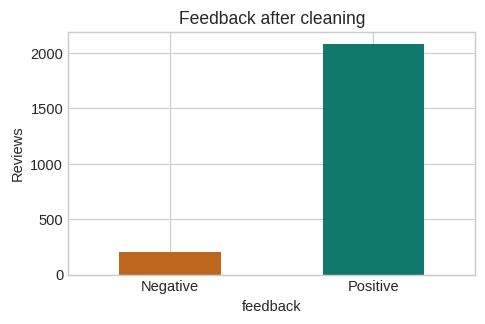

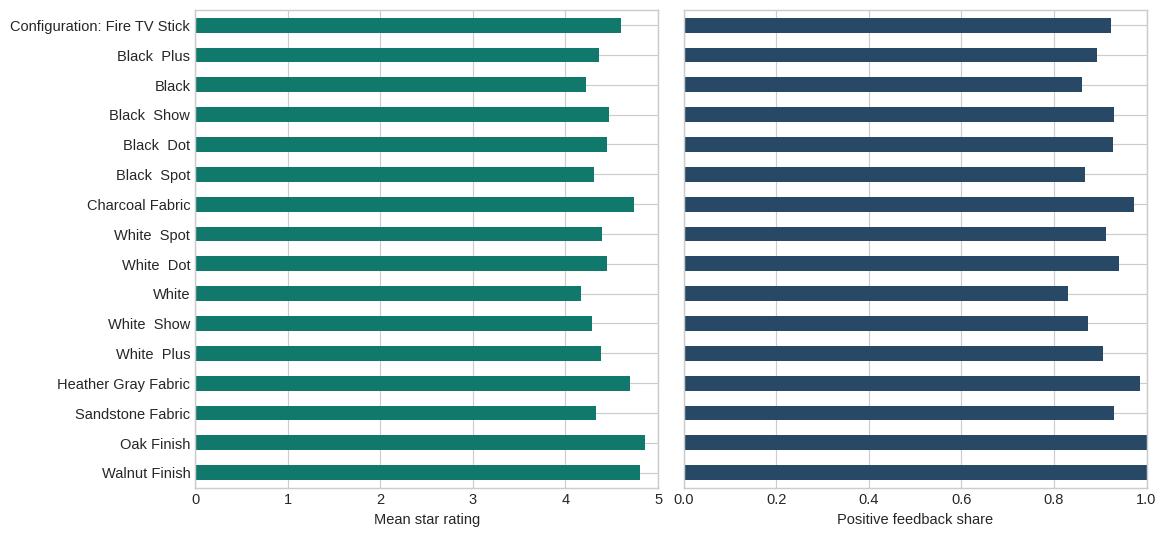

,mean_rating,positive_share,n
variation,,,
Walnut Finish,4.800,1.000,5
Oak Finish,4.857,1.000,7
Sandstone Fabric,4.326,0.930,43
Heather Gray Fabric,4.699,0.986,73
White Plus,4.378,0.905,74
White Show,4.291,0.873,79
White,4.171,0.829,82
White Dot,4.447,0.941,85
White Spot,4.392,0.912,102


feedback,0,1
rating,,
1,129,0
2,76,0
3,0,105
4,0,331
5,0,1649


,train,test
feedback,,
0,164,41
1,1668,417


In [ ]:
def normalize_review(text):
    return re.sub(r"\s+", " ", text).strip()

data = raw.copy()
data["verified_reviews"] = data["verified_reviews"].fillna("").map(normalize_review)
data["variation"] = data["variation"].fillna("Unknown").str.strip().replace("", "Unknown")
eligible = data["feedback"].isin([0, 1]) & data["verified_reviews"].ne("")
data = data.loc[eligible].copy()
data["review_key"] = data["verified_reviews"].str.casefold()
conflict = data.groupby("review_key")["feedback"].transform("nunique").gt(1)
clean = data.loc[~conflict].drop_duplicates("review_key").reset_index(drop=True)
print(f"Raw: {len(raw)} | Empty/invalid: {(~eligible).sum()} | Conflicting: {conflict.sum()} | "
      f"Duplicates: {len(data)-conflict.sum()-len(clean)} | Retained: {len(clean)}")

fig, ax = plt.subplots(figsize=(5, 3))
clean.feedback.map({0:"Negative", 1:"Positive"}).value_counts().reindex(
    ["Negative", "Positive"]).plot.bar(ax=ax, color=["#bd661d", "#11796c"], rot=0)
ax.set(title="Feedback after cleaning", ylabel="Reviews")
plt.show()

by_product = clean.groupby("variation").agg(
    mean_rating=("rating", "mean"), positive_share=("feedback", "mean"), n=("feedback", "size")
).sort_values("n")
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained", sharey=True)
by_product.mean_rating.plot.barh(ax=axes[0], color="#11796c", xlim=(0, 5))
by_product.positive_share.plot.barh(ax=axes[1], color="#284966", xlim=(0, 1))
axes[0].set(xlabel="Mean star rating", ylabel="")
axes[1].set(xlabel="Positive feedback share")
plt.show()
display(by_product.round(3))
display(pd.crosstab(clean["rating"], clean["feedback"]))

# Exclude date and stars. Using stars would leak information about the target.
X = clean[["verified_reviews", "variation"]]
y = clean["feedback"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
split_sizes = pd.DataFrame({"train":y_train.value_counts(), "test":y_test.value_counts()}).sort_index()
display(split_sizes)
split_sizes.to_csv(OUTPUT / "split.csv")

## 2. Feature engineering

Bag of Words contains unigram and bigram counts. TF-IDF downweights terms common across reviews and applies L2 normalization. Additional scaling is unnecessary. A sparse one-hot encoding of product variation is joined to either text matrix by the column transformer. For distributional embeddings, use a training-only word co-occurrence matrix with a four-token window and 32-dimensional truncated SVD. PCA projects selected normalized word vectors into two dimensions.

Nearest training-corpus neighbors (cosine similarity)
music  →  play, playing, or, etc, get
connect  →  connected, link, bluetooth, app, via
returned  →  four, issues, months, weeks, few


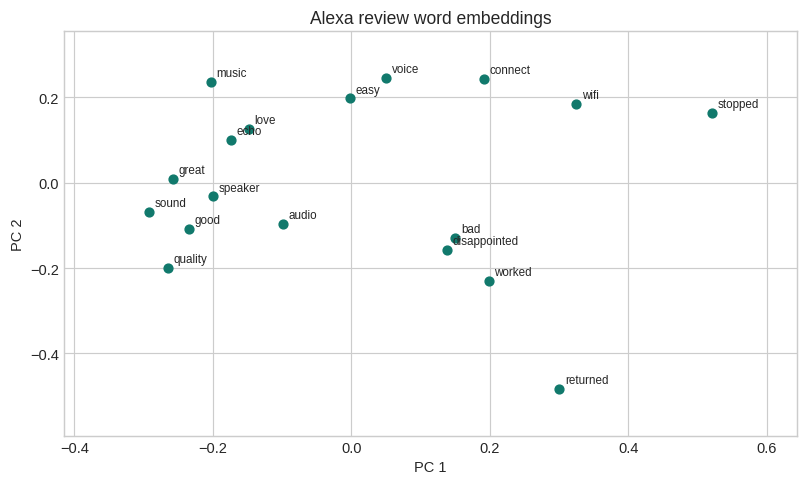

In [ ]:
def combined_features(vectorizer):
    return ColumnTransformer(
        [("text", vectorizer, "verified_reviews"),
         ("product", OneHotEncoder(handle_unknown="ignore"), ["variation"])],
        sparse_threshold=1.0,
    )

tokenize = CountVectorizer(token_pattern=r"(?u)\b[\w']{2,}\b").build_analyzer()
documents = [tokenize(review) for review in X_train.verified_reviews]
counts = Counter(word for document in documents for word in document)
words = [word for word, count in counts.most_common(1200) if count >= 3]
word_index = {word: i for i, word in enumerate(words)}
pairs = Counter()
for document in documents:
    for i, word in enumerate(document):
        if word in word_index:
            for j in range(max(0, i-4), min(len(document), i+5)):
                if j != i and document[j] in word_index:
                    pairs[word_index[word], word_index[document[j]]] += 1
rows, cols = zip(*pairs)
co_occurrence = coo_matrix(
    (np.log1p(list(pairs.values())), (rows, cols)), shape=(len(words), len(words))
).tocsr()
embeddings = TruncatedSVD(n_components=32, random_state=SEED).fit_transform(co_occurrence)
selected = [word for word in (
    "sound", "music", "speaker", "audio", "voice", "great", "good", "love", "easy",
    "worked", "stopped", "bad", "disappointed", "returned", "quality", "echo", "connect", "wifi"
) if word in word_index]
vectors = normalize(embeddings[[word_index[word] for word in selected]])
points = PCA(n_components=2).fit_transform(vectors)
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(*points.T, color="#11796c")
for word, point in zip(selected, points):
    ax.annotate(word, point, xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.margins(0.15)
ax.set(title="Alexa review word embeddings", xlabel="PC 1", ylabel="PC 2")
plt.show()
print("Nearest training-corpus neighbors (cosine similarity)")
normalized_embeddings = normalize(embeddings)
for term in ("music", "connect", "returned"):
    if term in word_index:
        scores = normalized_embeddings @ normalized_embeddings[word_index[term]]
        neighbors = [words[i] for i in np.argsort(scores)[::-1] if words[i] != term][:5]
        print(term, " → ", ", ".join(neighbors))

These neighbors describe contexts in the Alexa training corpus. The small corpus and two-dimensional projection limit conclusions about word meaning.

## 3. Traditional text classification

Train a 100-tree Random Forest with Bag of Words, plus Logistic Regression and Linear SVM with TF-IDF. Use three-fold stratified grid search and select by macro F1, giving both classes equal weight. The vocabulary and category encoder are fitted inside each fold. The majority-class classifier provides a baseline.

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
vector_params = dict(ngram_range=(1, 2), min_df=2)
specifications = {
    "Random Forest": (
        CountVectorizer(**vector_params),
        RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
        {"model__max_features": ["sqrt", 0.2],
         "model__class_weight": [None, "balanced_subsample"]},
    ),
    "Logistic regression": (
        TfidfVectorizer(**vector_params), LogisticRegression(max_iter=1000),
        {"model__C": [0.5, 2, 8], "model__class_weight": [None, "balanced"]},
    ),
    "Linear SVM": (
        TfidfVectorizer(**vector_params), LinearSVC(),
        {"model__C": [0.1, 1, 4], "model__class_weight": [None, "balanced"]},
    ),
}
models = {"Majority baseline": DummyClassifier(strategy="most_frequent").fit(X_train, y_train)}
for name, (vectorizer, model, grid) in specifications.items():
    pipeline = Pipeline([("features", combined_features(vectorizer)), ("model", model)])
    search = GridSearchCV(
        pipeline, grid, cv=cv, scoring=make_scorer(f1_score, average="macro", zero_division=0),
        n_jobs=1, error_score="raise"
    ).fit(X_train, y_train)
    models[name] = search.best_estimator_
    print(name, search.best_params_, f"mean CV macro F1 = {search.best_score_:.3f}")

Random Forest {'model__class_weight': 'balanced_subsample', 'model__max_features': 0.2} mean CV macro F1 = 0.661
Logistic regression {'model__C': 8, 'model__class_weight': 'balanced'} mean CV macro F1 = 0.748
Linear SVM {'model__C': 1, 'model__class_weight': 'balanced'} mean CV macro F1 = 0.745


## 4. Pretrained BERT for sentiment analysis

Fine-tune [BERT Tiny](https://huggingface.co/prajjwal1/bert-tiny), a pretrained two-layer BERT model, using only review text. Fine-tune the full encoder and classification head with class-weighted cross-entropy for up to four epochs. Select the epoch by macro F1 on a validation subset sampled from the training partition. All models share the same held-out test set. Select a GPU runtime in Colab for a faster run.

In [ ]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("transformers") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers==4.51.3"])

import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, set_seed

set_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = os.getenv("BERT_CHECKPOINT", "prajjwal1/bert-tiny")
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
bert = AutoModelForSequenceClassification.from_pretrained(
    checkpoint, num_labels=2, id2label={0:"Negative", 1:"Positive"},
    label2id={"Negative":0, "Positive":1}
).to(device)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED
)

def make_loader(frame, labels, shuffle=False):
    enc = tokenizer(frame.verified_reviews.tolist(), padding="max_length", truncation=True,
                    max_length=96, return_tensors="pt")
    tokens = TensorDataset(enc["input_ids"], enc["attention_mask"],
                           torch.tensor(labels.to_numpy(), dtype=torch.long))
    return DataLoader(tokens, batch_size=32, shuffle=shuffle)

weights = len(y_fit) / (2 * np.bincount(y_fit, minlength=2))
criterion = torch.nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=device))
optimizer = torch.optim.AdamW(bert.parameters(), lr=5e-5)
training = make_loader(X_fit, y_fit, shuffle=True)
validation = make_loader(X_val, y_val)

@torch.inference_mode()
def bert_predict(loader):
    bert.eval()
    batches = []
    for ids, mask, _ in loader:
        logits = bert(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
        batches.append(logits.softmax(dim=1).cpu().numpy())
    return np.concatenate(batches)

best_f1 = -1
for epoch in range(1, 5):
    bert.train()
    batch_losses = []
    for ids, mask, labels in training:
        optimizer.zero_grad()
        logits = bert(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
        loss = criterion(logits, labels.to(device))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(bert.parameters(), 1.0)
        optimizer.step()
        batch_losses.append(loss.item())
    validation_f1 = f1_score(y_val, bert_predict(validation).argmax(axis=1), average="macro")
    print(f"Epoch {epoch}: loss {np.mean(batch_losses):.3f} | validation macro F1 {validation_f1:.3f}", flush=True)
    if validation_f1 > best_f1:
        best_f1 = validation_f1
        best_state = {name: tensor.detach().cpu().clone() for name, tensor in bert.state_dict().items()}
bert.load_state_dict(best_state)
bert_probabilities = bert_predict(make_loader(X_test, y_test))

Epoch 1: loss 0.683 | validation macro F1 0.627
Epoch 2: loss 0.634 | validation macro F1 0.607
Epoch 3: loss 0.574 | validation macro F1 0.656
Epoch 4: loss 0.504 | validation macro F1 0.679


## 5. Model evaluation

Use accuracy, macro precision, macro recall, macro F1 and ROC-AUC. Also report negative recall to show the share of complaints each classifier catches. ROC curves use probability or decision scores for the positive class. Only the held-out test partition is used below.

In [ ]:
predictions = {}
for name, model in models.items():
    score = (model.decision_function(X_test) if hasattr(model, "decision_function")
             else model.predict_proba(X_test)[:, 1])
    predictions[name] = (model.predict(X_test), score)
predictions["BERT Tiny"] = (bert_probabilities.argmax(axis=1), bert_probabilities[:, 1])

records = []
for name, (pred, score) in predictions.items():
    records.append({
        "Model": name, "Accuracy": accuracy_score(y_test, pred),
        "Macro precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, score),
        "Negative recall": recall_score(y_test, pred, pos_label=0, zero_division=0),
        "Negatives caught": int(((y_test == 0) & (pred == 0)).sum()),
    })
    print(name)
    print(classification_report(y_test, pred, labels=[0, 1],
                                target_names=["Negative", "Positive"], zero_division=0))
metrics = pd.DataFrame(records).set_index("Model")
display(metrics.round(3))
metrics.to_csv(OUTPUT / "metrics.csv")
best = metrics["Macro F1"].idxmax()
print(f"Highest observed test macro F1: {best} ({metrics.loc[best, 'Macro F1']:.3f}).")
forest = models["Random Forest"]
train_accuracy = forest.score(X_train, y_train)
test_accuracy = forest.score(X_test, y_test)
print(f"Random Forest train accuracy: {train_accuracy:.3f} | test accuracy: {test_accuracy:.3f}")
(OUTPUT / "forest_train.txt").write_text(str(train_accuracy))
if train_accuracy - test_accuracy > 0.03:
    print("The training advantage suggests overfitting. Review negative recall before deployment.")

Majority baseline
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00        41
    Positive       0.91      1.00      0.95       417

    accuracy                           0.91       458
   macro avg       0.46      0.50      0.48       458
weighted avg       0.83      0.91      0.87       458

Random Forest
              precision    recall  f1-score   support

    Negative       0.59      0.32      0.41        41
    Positive       0.94      0.98      0.96       417

    accuracy                           0.92       458
   macro avg       0.76      0.65      0.68       458
weighted avg       0.90      0.92      0.91       458

Logistic regression
              precision    recall  f1-score   support

    Negative       0.56      0.44      0.49        41
    Positive       0.95      0.97      0.96       417

    accuracy                           0.92       458
   macro avg       0.75      0.70      0.72       458
weighted avg       0.9

,Accuracy,Macro precision,Macro recall,Macro F1,ROC-AUC,Negative recall,Negatives caught
Model,,,,,,,
Majority baseline,0.910,0.455,0.500,0.477,0.500,0.000,0
Random Forest,0.919,0.763,0.648,0.685,0.868,0.317,13
Logistic regression,0.919,0.754,0.703,0.725,0.912,0.439,18
Linear SVM,0.921,0.765,0.693,0.722,0.908,0.415,17
BERT Tiny,0.830,0.643,0.797,0.671,0.888,0.756,31


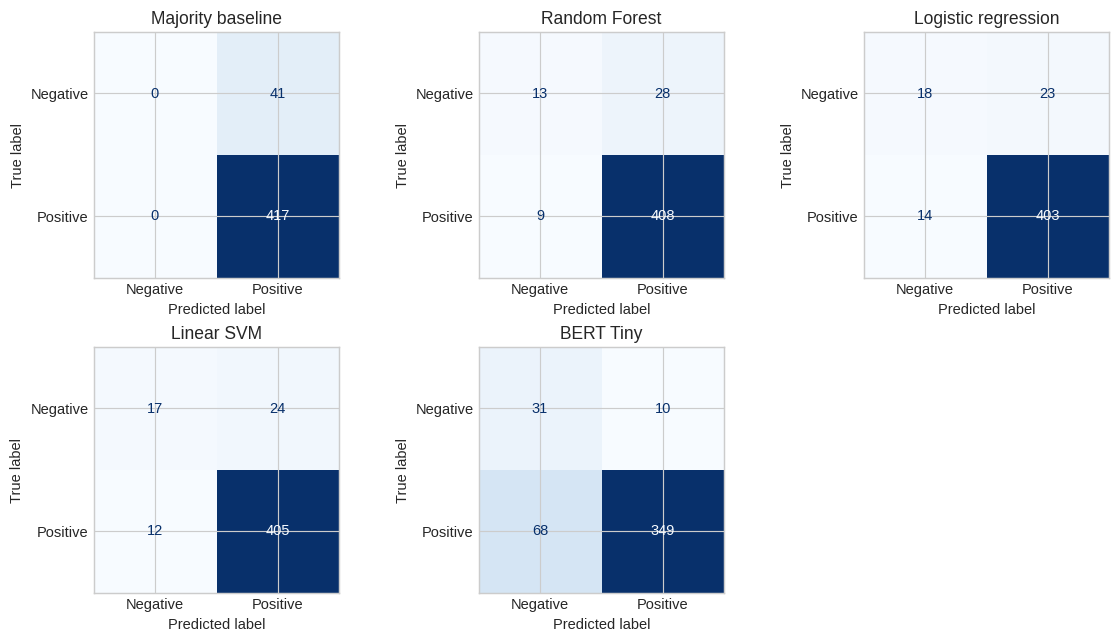

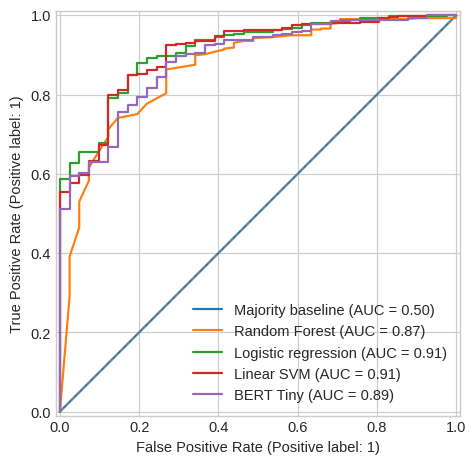

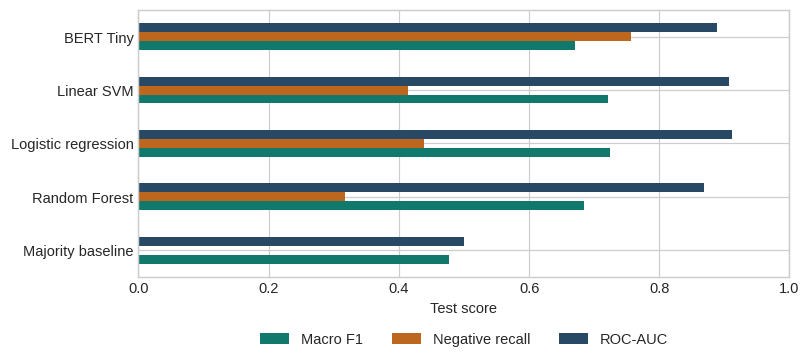

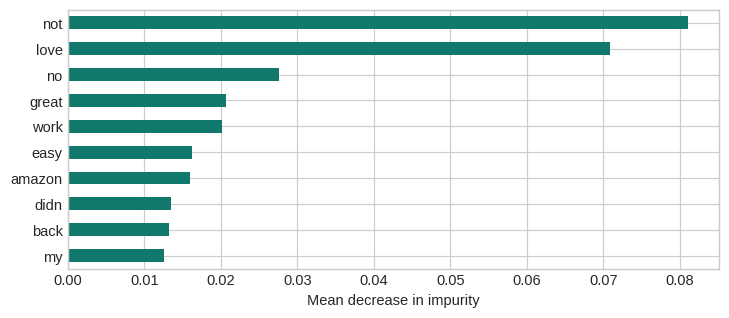

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
for ax, (name, (pred, _)) in zip(axs.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Negative", "Positive"],
                                           ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
axs.flat[-1].set_visible(False)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, (_, score) in predictions.items():
    RocCurveDisplay.from_predictions(y_test, score, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
plt.show()

ax = metrics[["Macro F1", "Negative recall", "ROC-AUC"]].plot.barh(
    figsize=(8, 3.3), color=["#11796c", "#bd661d", "#284966"], xlim=(0, 1)
)
ax.set(xlabel="Test score", ylabel="")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)
ax.figure.savefig(OUTPUT / "performance.png", dpi=200, bbox_inches="tight")
plt.show()

features = forest.named_steps["features"].get_feature_names_out()
importance = pd.Series(forest.named_steps["model"].feature_importances_, index=features)
top_features = importance.nlargest(10).sort_values()
top_features.index = (top_features.index.str.replace("text__", "", regex=False)
                      .str.replace("product__variation_", "Product: ", regex=False))
ax = top_features.plot.barh(figsize=(8, 3.2), color="#11796c")
ax.set(xlabel="Mean decrease in impurity", ylabel="")
ax.figure.savefig(OUTPUT / "importance.png", dpi=200, bbox_inches="tight")
plt.show()

Impurity-based importance measures how much a term or product contributes to forest splits. It gives no direction of sentiment and can favor frequent features. The minority class has relatively few test examples, so its recall is sensitive to individual reviews. Differences between BERT and the traditional models also reflect their input features and training procedures.

In [ ]:
def predict_sentiment(review, variation="Unknown"):
    review = normalize_review(review)
    if not review:
        raise ValueError("Enter a non-empty review.")
    row = pd.DataFrame({"verified_reviews": [review], "variation": [variation.strip() or "Unknown"]})
    return "Positive" if forest.predict(row)[0] else "Negative"

for review in ["I love my Alexa device! It's so helpful.",
               "It stopped working and I returned it."]:
    print(f"{predict_sentiment(review):8s} | {review}")

Positive | I love my Alexa device! It's so helpful.
Negative | It stopped working and I returned it.


## 6. Report and deployment strategy

The two-page PDF summarizes the results. Begin with shadow scoring and manual review of a sample of current Alexa reviews. Select a model and set a complaint-routing threshold on independent validation data based on the required negative recall and available review capacity. Version the preprocessing pipeline with its classifier. For BERT, version the tokenizer, weights and token limit together. Monitor complaint recall by product variation, label and score drift, and queue volume. Validate any retrained model on a later time window before deployment.